# 12 — Heat Accessibility and Mobility Link

This notebook compares modeled heat-conditioned accessibility loss with observed hot-day mobility reduction across Sevilla districts.

The objective is exploratory:

- aggregate modeled accessibility loss spatially;
- align it with district-level observed mobility change;
- test whether areas with larger modeled thermal-accessibility penalties also show larger mobility reductions on hot days.

The analysis is associative and does not establish causality.

In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

ACCESSIBILITY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "accessibility"
)

MOBILE_PROCESSED = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "processed"
)

MOBILE_INTERIM = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "interim"
)

In [2]:
mobility = pd.read_parquet(
    MOBILE_PROCESSED
    / "sevilla_district_hot_reference_mobility.parquet"
)

mobility

,id_origin,district_name,district_population,reference,hot,change_pct
0,4109105,Sevilla distrito 05,68916.0,199057.88275,161321.5184,-18.957483
1,4109103,Sevilla distrito 03,50394.0,140221.46800,114626.1748,-18.253477
2,4109101,Sevilla distrito 01,54914.0,178271.47150,145845.4648,-18.189117
3,4109110,Sevilla distrito 10,41589.0,106950.90175,88074.7310,-17.649380
4,4109111,Sevilla distrito 11,25033.0,60734.93050,50959.6002,-16.095071
5,4109106,Sevilla distrito 06,46253.0,123400.16850,103737.8264,-15.933805
6,4109108,Sevilla distrito 08,59239.0,181766.99075,155472.0102,-14.466312
7,4109107,Sevilla distrito 07,72030.0,157761.96925,137393.7560,-12.910725
8,4109102,Sevilla distrito 02,73367.0,153318.06200,133963.0940,-12.624063
9,4109109,Sevilla distrito 09,104255.0,231502.02550,202560.8898,-12.501461


In [3]:
access = pd.read_csv(
    ACCESSIBILITY_DIR
    / "origin_accessibility_lambda_005.csv"
)

print(access.shape)
print(access.columns.tolist())

access.head()

(49, 5)
['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']


,origin,normal_access,thermal_access,access_loss,access_loss_pct
0,12705553216,27,16,11,40.740741
1,10215553612,40,19,21,52.500000
2,2448671721,29,19,10,34.482759
3,5959692077,18,10,8,44.444444
4,13031291689,31,13,18,58.064516


In [4]:
zones = gpd.read_file(
    MOBILE_INTERIM
    / "sevilla_districts_v2.gpkg"
)

print(zones.crs)
zones[
    [
        "id",
        "name",
        "population"
    ]
]

EPSG:3042


,id,name,population
0,4109101,Sevilla distrito 01,54914.0
1,4109102,Sevilla distrito 02,73367.0
2,4109103,Sevilla distrito 03,50394.0
3,4109104,Sevilla distrito 04,88244.0
4,4109105,Sevilla distrito 05,68916.0
5,4109106,Sevilla distrito 06,46253.0
6,4109107,Sevilla distrito 07,72030.0
7,4109108,Sevilla distrito 08,59239.0
8,4109109,Sevilla distrito 09,104255.0
9,4109110,Sevilla distrito 10,41589.0


In [5]:
access.columns.tolist()

['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']

In [6]:
print(access.columns.tolist())
access.head()


['origin', 'normal_access', 'thermal_access', 'access_loss', 'access_loss_pct']


,origin,normal_access,thermal_access,access_loss,access_loss_pct
0,12705553216,27,16,11,40.740741
1,10215553612,40,19,21,52.500000
2,2448671721,29,19,10,34.482759
3,5959692077,18,10,8,44.444444
4,13031291689,31,13,18,58.064516


In [7]:
import osmnx as ox

THERMAL_GRAPH = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "sevilla_walk_thermal.graphml"
)

G = ox.load_graphml(THERMAL_GRAPH)

print(
    "Graph:",
    len(G.nodes),
    "nodes,",
    len(G.edges),
    "edges"
)
print("CRS:", G.graph["crs"])

Graph: 1630 nodes, 4612 edges
CRS: EPSG:25830


In [8]:
nodes, edges = ox.graph_to_gdfs(G)

nodes = nodes.reset_index()

print(nodes.columns.tolist())
nodes.head()

['osmid', 'y', 'x', 'street_count', 'highway', 'ref', 'geometry']


,osmid,y,x,street_count,highway,ref,geometry
0,304499541,4.141999e+06,237253.283395,4,traffic_signals,NaN,POINT (237253.283 4141998.882)
1,1957097246,4.142026e+06,237253.690044,3,NaN,NaN,POINT (237253.69 4142026.442)
2,2528424748,4.141995e+06,237369.340641,3,NaN,NaN,POINT (237369.341 4141994.618)
3,421923023,4.141996e+06,237137.989463,3,NaN,NaN,POINT (237137.989 4141996.425)
4,12111584428,4.141986e+06,237253.016431,4,crossing,NaN,POINT (237253.016 4141986.46)


In [9]:
nodes["osmid"] = nodes["osmid"].astype(str)
access["origin"] = access["origin"].astype(str)

access_origins = nodes[
    nodes["osmid"].isin(access["origin"])
].copy()

print(
    "Accessibility origins found:",
    len(access_origins),
    "/",
    len(access)
)

Accessibility origins found: 49 / 49


In [11]:
access_origins = access_origins.merge(
    access,
    left_on="osmid",
    right_on="origin",
    how="inner"
)

access_origins[
    [
        "origin",
        "normal_access",
        "thermal_access",
        "access_loss_pct",
        "geometry"
    ]
].head()

,origin,normal_access,thermal_access,access_loss_pct,geometry
0,3859840024,43,24,44.186047,POINT (237989.2 4141956.241)
1,1968780510,15,7,53.333333,POINT (239276.578 4143246.392)
2,10215553612,40,19,52.500000,POINT (237509.555 4142701.726)
3,12146727285,39,16,58.974359,POINT (238103.421 4142889.625)
4,405557071,27,13,51.851852,POINT (237260.237 4142272.7)


In [12]:
zones_graph = zones.to_crs(
    access_origins.crs
)

print("Origins CRS:", access_origins.crs)
print("Zones CRS:", zones_graph.crs)

Origins CRS: EPSG:25830
Zones CRS: EPSG:25830


In [13]:
origins_district = gpd.sjoin(
    access_origins,
    zones_graph[
        [
            "id",
            "name",
            "geometry"
        ]
    ],
    how="left",
    predicate="within"
)

origins_district[
    [
        "origin",
        "name",
        "access_loss_pct"
    ]
].head()

,origin,name,access_loss_pct
0,3859840024,Sevilla distrito 03,44.186047
1,1968780510,Sevilla distrito 08,53.333333
2,10215553612,Sevilla distrito 08,52.500000
3,12146727285,Sevilla distrito 08,58.974359
4,405557071,Sevilla distrito 08,51.851852


In [14]:
print(
    "Origins assigned to districts:",
    origins_district["id"].notna().sum(),
    "/",
    len(origins_district)
)

print(
    origins_district["name"]
    .value_counts(dropna=False)
)

Origins assigned to districts: 49 / 49
name
Sevilla distrito 08    38
Sevilla distrito 04     9
Sevilla distrito 03     2
Name: count, dtype: int64


In [16]:
district_access = (
    origins_district
    .groupby(
        ["id", "name"],
        as_index=False
    )
    .agg(
        n_origins=("origin", "size"),
        mean_access_loss_pct=("access_loss_pct", "mean"),
        median_access_loss_pct=("access_loss_pct", "median"),
        mean_normal_access=("normal_access", "mean"),
        mean_thermal_access=("thermal_access", "mean")
    )
)

district_access

,id,name,n_origins,mean_access_loss_pct,median_access_loss_pct,mean_normal_access,mean_thermal_access
0,4109103,Sevilla distrito 03,2,52.975376,52.975376,38.500000,18.5
1,4109104,Sevilla distrito 04,9,45.348780,44.444444,18.666667,10.0
2,4109108,Sevilla distrito 08,38,52.972045,52.175926,27.500000,13.0


In [17]:
mobility["id_origin"] = mobility["id_origin"].astype(str)
district_access["id"] = district_access["id"].astype(str)

linked = district_access.merge(
    mobility[
        [
            "id_origin",
            "district_name",
            "change_pct"
        ]
    ],
    left_on="id",
    right_on="id_origin",
    how="left"
)

linked[
    [
        "name",
        "n_origins",
        "mean_access_loss_pct",
        "change_pct"
    ]
]

,name,n_origins,mean_access_loss_pct,change_pct
0,Sevilla distrito 03,2,52.975376,-18.253477
1,Sevilla distrito 04,9,45.348780,-9.976968
2,Sevilla distrito 08,38,52.972045,-14.466312


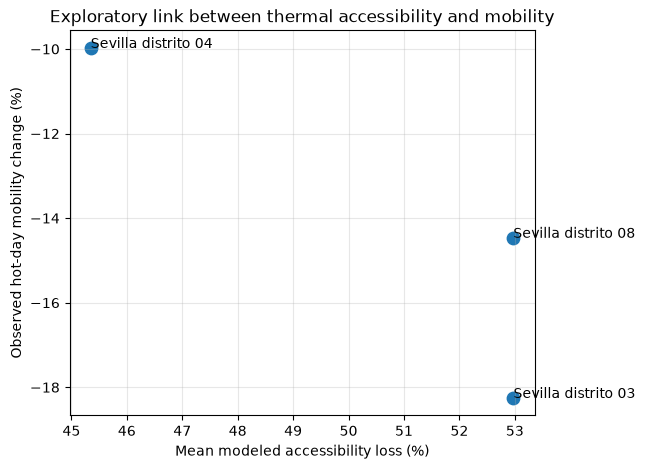

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    linked["mean_access_loss_pct"],
    linked["change_pct"],
    s=80
)

for _, row in linked.iterrows():
    ax.annotate(
        row["name"],
        (
            row["mean_access_loss_pct"],
            row["change_pct"]
        )
    )

ax.set_xlabel("Mean modeled accessibility loss (%)")
ax.set_ylabel("Observed hot-day mobility change (%)")
ax.set_title(
    "Exploratory link between thermal accessibility and mobility"
)

ax.grid(alpha=0.3)

plt.show()

## Opportunity-weighted network loss

Reachable network contraction alone showed only a weak relationship with accessibility loss. This section examines whether the accessibility impact of thermal impedance depends on which transit opportunities become unreachable.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

INTERIM = PROJECT_ROOT / "data" / "interim"

ACCESSIBILITY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "accessibility"
)

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

INTERIM = PROJECT_ROOT / "data" / "interim"

ACCESSIBILITY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "accessibility"
)

In [3]:
G = ox.load_graphml(
    INTERIM / "sevilla_walk_thermal.graphml"
)

numeric_edge_fields = [
    "length",
    "walk_time_s",
    "utci_max",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
]

for u, v, k, data in G.edges(
    keys=True,
    data=True
):
    for field in numeric_edge_fields:
        if field in data:
            try:
                data[field] = float(data[field])
            except (TypeError, ValueError):
                data[field] = np.nan

In [4]:
access = pd.read_csv(
    ACCESSIBILITY_DIR
    / "origin_accessibility_lambda_005.csv"
)

access["origin"] = access["origin"].astype(str)

graph_node_lookup = {
    str(node): node
    for node in G.nodes
}

access["origin_graph"] = (
    access["origin"]
    .map(graph_node_lookup)
)

print(
    "Origins matched:",
    access["origin_graph"].notna().sum(),
    "/",
    len(access)
)

Origins matched: 49 / 49


In [5]:
candidate_files = list(
    PROJECT_ROOT.rglob("*stop*")
)

for f in candidate_files:
    print(f.relative_to(PROJECT_ROOT))

In [6]:
candidate_files = list(
    PROJECT_ROOT.rglob("*transit*")
)

for f in candidate_files:
    print(f.relative_to(PROJECT_ROOT))

In [7]:
candidate_files = list(
    PROJECT_ROOT.rglob("*gtfs*")
)

for f in candidate_files:
    print(f.relative_to(PROJECT_ROOT))

## Reconstruct transit-stop opportunities

Transit opportunities are reconstructed using the same OSM feature definitions and network-snapping procedure used in Notebook 07.

In [9]:
import geopandas as gpd
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

THERMAL_GRAPH = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "sevilla_walk_thermal.graphml"
)

G = ox.load_graphml(THERMAL_GRAPH)

# Convert GraphML attributes back to numeric
numeric_fields = [
    "length",
    "walk_time_s",
    "utci_max",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
]

for u, v, k, data in G.edges(keys=True, data=True):
    for field in numeric_fields:
        if field in data:
            try:
                data[field] = float(data[field])
            except (TypeError, ValueError):
                data[field] = np.nan

In [10]:
nodes_all, edges_all = ox.graph_to_gdfs(G)

valid_mask = (
    edges_all["walk_time_s"].notna()
    & edges_all["heat_excess"].notna()
    & edges_all["thermal_cost_s"].notna()
)

edges_valid = edges_all.loc[valid_mask].copy()

valid_node_ids = (
    set(edges_valid.index.get_level_values("u"))
    | set(edges_valid.index.get_level_values("v"))
)

nodes_valid = nodes_all.loc[
    nodes_all.index.intersection(valid_node_ids)
].copy()

nodes_valid["x"] = nodes_valid.geometry.x
nodes_valid["y"] = nodes_valid.geometry.y

G_valid = ox.graph_from_gdfs(
    nodes_valid,
    edges_valid,
    graph_attrs={"crs": G.graph["crs"]}
)

largest_component = max(
    nx.strongly_connected_components(G_valid),
    key=len
)

G_main = G_valid.subgraph(
    largest_component
).copy()

print("Final nodes:", G_main.number_of_nodes())
print("Final edges:", G_main.number_of_edges())

Final nodes: 1523
Final edges: 4392


In [11]:
from shapely.geometry import box

nodes_gdf, edges_gdf = ox.graph_to_gdfs(G_main)

thermal_polygon = (
    gpd.GeoSeries(
        [box(*edges_gdf.total_bounds)],
        crs=edges_gdf.crs
    )
    .to_crs(4326)
    .iloc[0]
)

tags = {
    "highway": "bus_stop",
    "public_transport": [
        "platform",
        "stop_position"
    ]
}

stops = ox.features_from_polygon(
    thermal_polygon,
    tags=tags
)

In [12]:
stops = stops[
    stops.geometry.type.isin(
        ["Point", "Polygon", "MultiPolygon"]
    )
].copy()

stops = stops.to_crs(
    G_main.graph["crs"]
)

stops["geometry"] = (
    stops.geometry.centroid
)

stops = stops.drop_duplicates(
    subset="geometry"
)

print("Transit features:", len(stops))

Transit features: 228


In [13]:
stops["node"] = ox.distance.nearest_nodes(
    G_main,
    X=stops.geometry.x.values,
    Y=stops.geometry.y.values
)

stop_nodes = list(
    pd.unique(stops["node"])
)

# Same final protection as notebook 07
stop_nodes = [
    node
    for node in stop_nodes
    if node in G_main
]

print("Unique stop nodes:", len(stop_nodes))

Unique stop nodes: 123


In [14]:
TIME_BUDGET = 600

graph_node_lookup = {
    str(node): node
    for node in G_main.nodes
}

access = pd.read_csv(
    ACCESSIBILITY_DIR
    / "origin_accessibility_lambda_005.csv"
)

access["origin"] = access["origin"].astype(str)

access["origin_graph"] = (
    access["origin"]
    .map(graph_node_lookup)
)

print(
    "Origins matched:",
    access["origin_graph"].notna().sum(),
    "/",
    len(access)
)

Origins matched: 49 / 49


In [15]:
results = []

for origin_str, origin in zip(
    access["origin"],
    access["origin_graph"]
):

    normal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=TIME_BUDGET,
        weight="walk_time_s"
    )

    thermal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=TIME_BUDGET,
        weight="thermal_cost_s"
    )

    normal_stops = {
        node
        for node in stop_nodes
        if node in normal_costs
    }

    thermal_stops = {
        node
        for node in stop_nodes
        if node in thermal_costs
    }

    lost_stops = normal_stops - thermal_stops

    results.append({
        "origin": origin_str,
        "normal_stop_count": len(normal_stops),
        "thermal_stop_count": len(thermal_stops),
        "lost_stop_count": len(lost_stops),
        "stop_loss_pct": (
            100 * len(lost_stops) / len(normal_stops)
            if len(normal_stops) > 0
            else np.nan
        ),
    })

stop_access = pd.DataFrame(results)

In [16]:
check = access.merge(
    stop_access,
    on="origin",
    how="left"
)

print(
    "Normal counts match:",
    (
        check["normal_access"]
        == check["normal_stop_count"]
    ).all()
)

print(
    "Thermal counts match:",
    (
        check["thermal_access"]
        == check["thermal_stop_count"]
    ).all()
)

print(
    "Max normal difference:",
    (
        check["normal_access"]
        - check["normal_stop_count"]
    ).abs().max()
)

print(
    "Max thermal difference:",
    (
        check["thermal_access"]
        - check["thermal_stop_count"]
    ).abs().max()
)

Normal counts match: False
Thermal counts match: False
Max normal difference: 1
Max thermal difference: 1


In [17]:
G_raw = ox.load_graphml(
    INTERIM / "sevilla_walk_thermal.graphml"
)

numeric_fields = [
    "length",
    "walk_time_s",
    "utci_max",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
]

for u, v, k, data in G_raw.edges(
    keys=True,
    data=True
):
    for field in numeric_fields:
        if field in data:
            try:
                data[field] = float(data[field])
            except (TypeError, ValueError):
                data[field] = np.nan


largest_component = max(
    nx.strongly_connected_components(G_raw),
    key=len
)

G_preclean = G_raw.subgraph(
    largest_component
).copy()

print(
    G_preclean.number_of_nodes(),
    G_preclean.number_of_edges()
)

1565 4494


In [18]:
nodes_pre, edges_pre = ox.graph_to_gdfs(
    G_preclean
)

from shapely.geometry import box

thermal_polygon = (
    gpd.GeoSeries(
        [box(*edges_pre.total_bounds)],
        crs=edges_pre.crs
    )
    .to_crs(4326)
    .iloc[0]
)

tags = {
    "highway": "bus_stop",
    "public_transport": [
        "platform",
        "stop_position"
    ]
}

stops = ox.features_from_polygon(
    thermal_polygon,
    tags=tags
)

stops = stops[
    stops.geometry.type.isin(
        ["Point", "Polygon", "MultiPolygon"]
    )
].copy()

stops = stops.to_crs(
    G_preclean.graph["crs"]
)

stops["geometry"] = stops.geometry.centroid

stops = stops.drop_duplicates(
    subset="geometry"
)

stops["node"] = ox.distance.nearest_nodes(
    G_preclean,
    X=stops.geometry.x.values,
    Y=stops.geometry.y.values
)

stop_nodes_preclean = list(
    pd.unique(stops["node"])
)

print(
    "Pre-clean unique stops:",
    len(stop_nodes_preclean)
)

Pre-clean unique stops: 139


In [19]:
nodes_all, edges_all = ox.graph_to_gdfs(
    G_preclean
)

edges_valid = edges_all[
    edges_all["walk_time_s"].notna()
    & edges_all["utci_max"].notna()
    & edges_all["heat_excess"].notna()
].copy()

valid_node_ids = (
    set(edges_valid.index.get_level_values("u"))
    | set(edges_valid.index.get_level_values("v"))
)

nodes_valid = nodes_all.loc[
    nodes_all.index.intersection(
        valid_node_ids
    )
].copy()

nodes_valid["x"] = nodes_valid.geometry.x
nodes_valid["y"] = nodes_valid.geometry.y

G_valid = ox.graph_from_gdfs(
    nodes_valid,
    edges_valid,
    graph_attrs={
        "crs": G_preclean.graph["crs"]
    }
)

largest_component = max(
    nx.strongly_connected_components(G_valid),
    key=len
)

G_main = G_valid.subgraph(
    largest_component
).copy()

print(
    "Final:",
    G_main.number_of_nodes(),
    G_main.number_of_edges()
)

Final: 1523 4392


In [20]:
stop_nodes = [
    node
    for node in stop_nodes_preclean
    if node in G_main
]

print(
    "Stops retained:",
    len(stop_nodes)
)

print(
    "Unique stops:",
    len(set(stop_nodes))
)

Stops retained: 129
Unique stops: 129


In [21]:
for u, v, k, data in G_main.edges(
    keys=True,
    data=True
):
    walk_time = float(
        data["walk_time_s"]
    )

    heat_excess = float(
        data["heat_excess"]
    )

    data["thermal_0.05"] = (
        walk_time
        * (1 + 0.05 * heat_excess)
    )

In [22]:
weight="thermal_0.05"

In [23]:
results = []

graph_node_lookup = {
    str(node): node
    for node in G_main.nodes
}

for _, row in access.iterrows():

    origin = graph_node_lookup[
        str(row["origin"])
    ]

    normal_costs = (
        nx.single_source_dijkstra_path_length(
            G_main,
            origin,
            cutoff=600,
            weight="walk_time_s"
        )
    )

    thermal_costs = (
        nx.single_source_dijkstra_path_length(
            G_main,
            origin,
            cutoff=600,
            weight="thermal_0.05"
        )
    )

    normal_stops = {
        stop
        for stop in stop_nodes
        if stop in normal_costs
    }

    thermal_stops = {
        stop
        for stop in stop_nodes
        if stop in thermal_costs
    }

    results.append({
        "origin": str(row["origin"]),
        "normal_stop_count":
            len(normal_stops),
        "thermal_stop_count":
            len(thermal_stops),
        "lost_stop_count":
            len(
                normal_stops
                - thermal_stops
            ),
    })

stop_access = pd.DataFrame(results)

In [24]:
check = (
    access
    .assign(
        origin=access[
            "origin"
        ].astype(str)
    )
    .merge(
        stop_access,
        on="origin",
        how="left"
    )
)

print(
    "Normal counts match:",
    (
        check["normal_access"]
        == check["normal_stop_count"]
    ).all()
)

print(
    "Thermal counts match:",
    (
        check["thermal_access"]
        == check["thermal_stop_count"]
    ).all()
)

print(
    "Max normal difference:",
    (
        check["normal_access"]
        - check["normal_stop_count"]
    ).abs().max()
)

print(
    "Max thermal difference:",
    (
        check["thermal_access"]
        - check["thermal_stop_count"]
    ).abs().max()
)

Normal counts match: True
Thermal counts match: True
Max normal difference: 0
Max thermal difference: 0


In [25]:
lost_stop_records = []

for _, row in access.iterrows():

    origin = graph_node_lookup[
        str(row["origin"])
    ]

    normal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=600,
        weight="walk_time_s"
    )

    thermal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=600,
        weight="thermal_0.05"
    )

    normal_stops = {
        stop
        for stop in stop_nodes
        if stop in normal_costs
    }

    thermal_stops = {
        stop
        for stop in stop_nodes
        if stop in thermal_costs
    }

    lost_stops = normal_stops - thermal_stops

    for stop in lost_stops:
        lost_stop_records.append({
            "origin": str(row["origin"]),
            "stop_node": stop,
            "normal_cost_s": normal_costs[stop]
        })

lost_stops_df = pd.DataFrame(
    lost_stop_records
)

lost_stops_df.head()

,origin,stop_node,normal_cost_s
0,12705553216,13140716035,554.173440
1,12705553216,13140716036,597.469116
2,12705553216,13169268197,538.204793
3,12705553216,864118918,523.751467
4,12705553216,2483779590,514.829178


In [26]:
stop_loss_frequency = (
    lost_stops_df
    .groupby(
        "stop_node",
        as_index=False
    )
    .agg(
        origins_losing_stop=(
            "origin",
            "nunique"
        ),
        mean_normal_cost_s=(
            "normal_cost_s",
            "mean"
        )
    )
    .sort_values(
        "origins_losing_stop",
        ascending=False
    )
)

stop_loss_frequency.head(15)

,stop_node,origins_losing_stop,mean_normal_cost_s
29,746303153,13,495.490227
99,12697308465,13,508.209200
101,12697308498,13,517.257686
102,12697308559,12,512.823158
100,12697308468,12,513.112523
103,12697308560,12,515.485040
74,9910479332,11,494.978327
83,11169378354,11,500.842357
89,12146727290,11,489.855441
31,765623229,11,533.688306


In [27]:
nodes_gdf, _ = ox.graph_to_gdfs(
    G_main
)

stop_loss_geo = (
    nodes_gdf[
        ["geometry"]
    ]
    .reset_index()
    .rename(
        columns={
            "osmid": "stop_node"
        }
    )
)

stop_loss_geo["stop_node"] = (
    stop_loss_geo["stop_node"]
    .astype(int)
)

stop_loss_frequency = (
    stop_loss_frequency
    .merge(
        stop_loss_geo,
        on="stop_node",
        how="left"
    )
)

stop_loss_frequency = gpd.GeoDataFrame(
    stop_loss_frequency,
    geometry="geometry",
    crs=nodes_gdf.crs
)

In [28]:
TIME_BUDGET = 600

stop_loss_frequency[
    "mean_margin_to_budget_s"
] = (
    TIME_BUDGET
    - stop_loss_frequency["mean_normal_cost_s"]
)

stop_loss_frequency[
    [
        "stop_node",
        "origins_losing_stop",
        "mean_normal_cost_s",
        "mean_margin_to_budget_s"
    ]
].head(15)

,stop_node,origins_losing_stop,mean_normal_cost_s,mean_margin_to_budget_s
0,746303153,13,495.490227,104.509773
1,12697308465,13,508.209200,91.790800
2,12697308498,13,517.257686,82.742314
3,12697308559,12,512.823158,87.176842
4,12697308468,12,513.112523,86.887477
5,12697308560,12,515.485040,84.514960
6,9910479332,11,494.978327,105.021673
7,11169378354,11,500.842357,99.157643
8,12146727290,11,489.855441,110.144559
9,765623229,11,533.688306,66.311694


In [29]:
N_ORIGINS = len(access)

stop_loss_frequency[
    "share_origins_losing_pct"
] = (
    stop_loss_frequency[
        "origins_losing_stop"
    ]
    / N_ORIGINS
    * 100
)

stop_loss_frequency[
    [
        "stop_node",
        "origins_losing_stop",
        "share_origins_losing_pct",
        "mean_normal_cost_s",
        "mean_margin_to_budget_s"
    ]
].head(15)

,stop_node,origins_losing_stop,share_origins_losing_pct,mean_normal_cost_s,mean_margin_to_budget_s
0,746303153,13,26.530612,495.490227,104.509773
1,12697308465,13,26.530612,508.209200,91.790800
2,12697308498,13,26.530612,517.257686,82.742314
3,12697308559,12,24.489796,512.823158,87.176842
4,12697308468,12,24.489796,513.112523,86.887477
5,12697308560,12,24.489796,515.485040,84.514960
6,9910479332,11,22.448980,494.978327,105.021673
7,11169378354,11,22.448980,500.842357,99.157643
8,12146727290,11,22.448980,489.855441,110.144559
9,765623229,11,22.448980,533.688306,66.311694


In [30]:
lost_summary = stop_loss_frequency[
    [
        "origins_losing_stop",
        "share_origins_losing_pct",
        "mean_normal_cost_s",
        "mean_margin_to_budget_s"
    ]
].describe()

lost_summary

,origins_losing_stop,share_origins_losing_pct,mean_normal_cost_s,mean_margin_to_budget_s
count,117.000000,117.000000,117.000000,117.000000
mean,5.717949,11.669283,517.213568,82.786432
std,3.022462,6.168290,30.449351,30.449351
min,2.000000,4.081633,434.715309,6.514135
25%,3.000000,6.122449,497.668049,65.347952
50%,5.000000,10.204082,513.999528,86.000472
75%,8.000000,16.326531,534.652048,102.331951
max,13.000000,26.530612,593.485865,165.284691


In [31]:
print(
    "Unique stops lost at least once:",
    len(stop_loss_frequency)
)

print(
    "Mean normal cost of lost stops:",
    f"{stop_loss_frequency['mean_normal_cost_s'].mean():.1f} s"
)

print(
    "Mean remaining normal-time margin:",
    f"{stop_loss_frequency['mean_margin_to_budget_s'].mean():.1f} s"
)

Unique stops lost at least once: 117
Mean normal cost of lost stops: 517.2 s
Mean remaining normal-time margin: 82.8 s


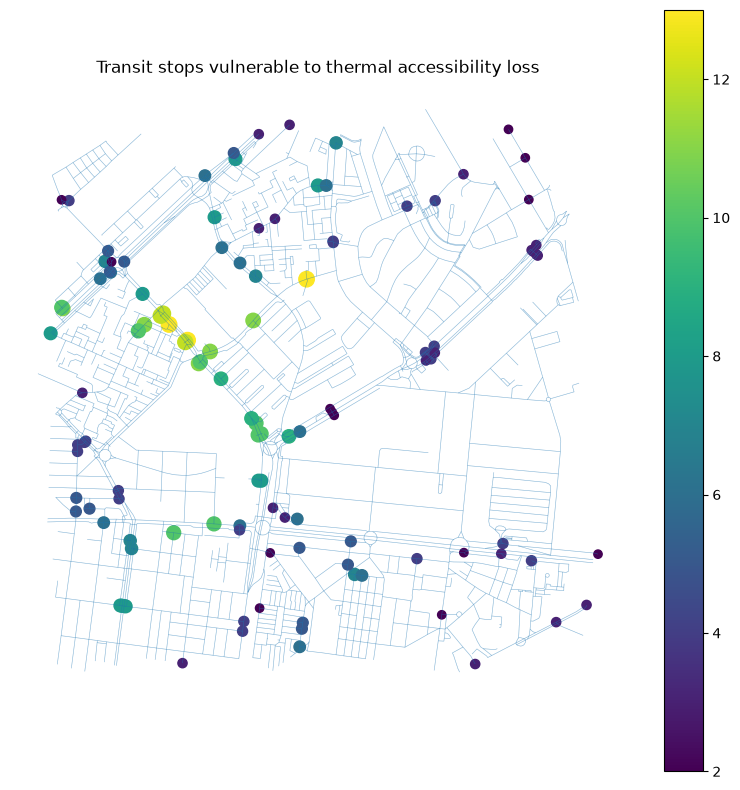

In [33]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(8, 8)
)

edges_plot = ox.graph_to_gdfs(
    G_main,
    nodes=False
)

edges_plot.plot(
    ax=ax,
    linewidth=0.4,
    alpha=0.3
)

stop_loss_frequency.plot(
    ax=ax,
    column="origins_losing_stop",
    markersize=(
        20
        + stop_loss_frequency[
            "origins_losing_stop"
        ] * 8
    ),
    legend=True
)

ax.set_title(
    "Transit stops vulnerable to thermal accessibility loss"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [34]:
from scipy.stats import pearsonr, spearmanr

x = stop_loss_frequency[
    "mean_margin_to_budget_s"
]

y = stop_loss_frequency[
    "origins_losing_stop"
]

pearson_r, pearson_p = pearsonr(x, y)
spearman_rho, spearman_p = spearmanr(x, y)

print(
    f"Pearson r: {pearson_r:.3f}, "
    f"p = {pearson_p:.4f}"
)

print(
    f"Spearman rho: {spearman_rho:.3f}, "
    f"p = {spearman_p:.4f}"
)

Pearson r: 0.233, p = 0.0115
Spearman rho: 0.286, p = 0.0018


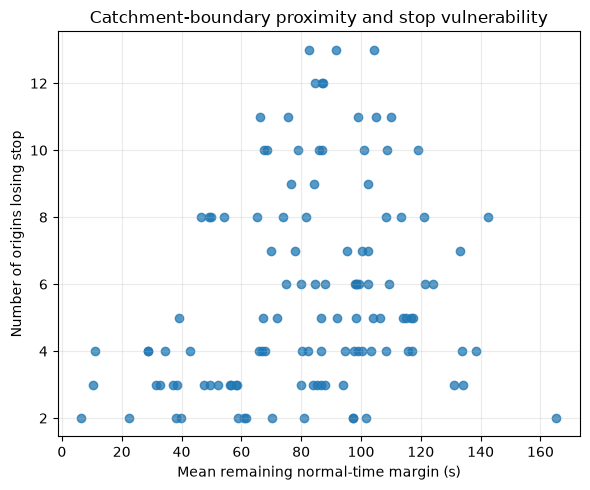

In [35]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

ax.scatter(
    stop_loss_frequency[
        "mean_margin_to_budget_s"
    ],
    stop_loss_frequency[
        "origins_losing_stop"
    ],
    alpha=0.75
)

ax.set_xlabel(
    "Mean remaining normal-time margin (s)"
)

ax.set_ylabel(
    "Number of origins losing stop"
)

ax.set_title(
    "Catchment-boundary proximity and stop vulnerability"
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [36]:
pair_records = []

for _, row in access.iterrows():

    origin_str = str(row["origin"])
    origin = graph_node_lookup[origin_str]

    normal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=600,
        weight="walk_time_s"
    )

    thermal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=600,
        weight="thermal_0.05"
    )

    for stop in stop_nodes:

        # Only opportunities reachable under normal conditions
        if stop not in normal_costs:
            continue

        normal_cost = normal_costs[stop]

        pair_records.append({
            "origin": origin_str,
            "stop_node": stop,
            "normal_cost_s": normal_cost,
            "margin_to_budget_s": 600 - normal_cost,
            "lost": int(stop not in thermal_costs),
        })

opportunity_pairs = pd.DataFrame(
    pair_records
)

opportunity_pairs.head()

,origin,stop_node,normal_cost_s,margin_to_budget_s,lost
0,12705553216,857186574,508.737440,91.262560,1
1,12705553216,2014236023,358.897239,241.102761,0
2,12705553216,12111568596,371.200172,228.799828,0
3,12705553216,13140716036,597.469116,2.530884,1
4,12705553216,13140716035,554.173440,45.826560,1


In [37]:
print(
    "Normally reachable origin-stop opportunities:",
    len(opportunity_pairs)
)

print(
    "Opportunities lost:",
    opportunity_pairs["lost"].sum()
)

print(
    "Overall loss rate:",
    f"{100 * opportunity_pairs['lost'].mean():.1f}%"
)

Normally reachable origin-stop opportunities: 1290
Opportunities lost: 669
Overall loss rate: 51.9%


In [38]:
opportunity_pairs.groupby(
    "lost"
)[
    [
        "normal_cost_s",
        "margin_to_budget_s"
    ]
].agg(
    ["count", "mean", "median", "std"]
)

normal_cost_s                                     margin_to_budget_s  \
             count        mean      median         std              count   
lost                                                                        
0              621  262.117397  281.022949  101.596159                621   
1              669  513.497145  517.469907   54.659712                669   

                                          
            mean      median         std  
lost                                      
0     337.882603  318.977051  101.596159  
1      86.502855   82.530093   54.659712

In [39]:
bins = [
    0,
    120,
    240,
    360,
    420,
    480,
    540,
    600
]

labels = [
    "0–2 min",
    "2–4 min",
    "4–6 min",
    "6–7 min",
    "7–8 min",
    "8–9 min",
    "9–10 min"
]

opportunity_pairs[
    "normal_cost_band"
] = pd.cut(
    opportunity_pairs["normal_cost_s"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

loss_by_band = (
    opportunity_pairs
    .groupby(
        "normal_cost_band",
        observed=True
    )
    .agg(
        opportunities=("lost", "size"),
        lost_opportunities=("lost", "sum"),
        loss_rate=("lost", "mean")
    )
    .reset_index()
)

loss_by_band["loss_rate_pct"] = (
    100 * loss_by_band["loss_rate"]
)

loss_by_band

,normal_cost_band,opportunities,lost_opportunities,loss_rate,loss_rate_pct
0,0–2 min,65,0,0.000000,0.000000
1,2–4 min,186,0,0.000000,0.000000
2,4–6 min,249,0,0.000000,0.000000
3,6–7 min,152,31,0.203947,20.394737
4,7–8 min,178,178,1.000000,100.000000
5,8–9 min,212,212,1.000000,100.000000
6,9–10 min,248,248,1.000000,100.000000


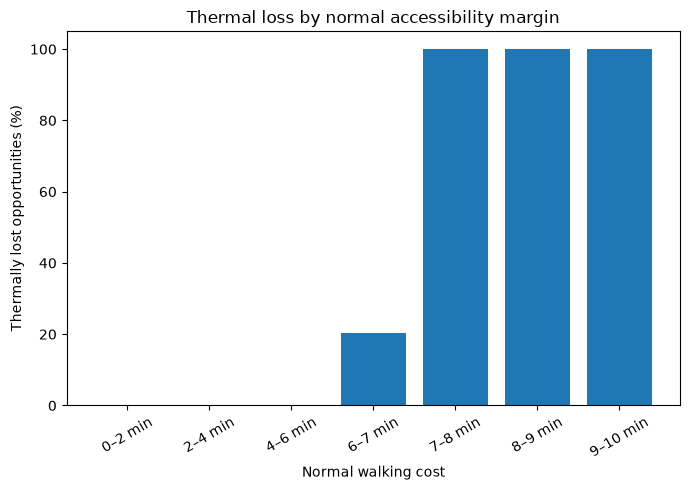

In [40]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    loss_by_band[
        "normal_cost_band"
    ].astype(str),
    loss_by_band[
        "loss_rate_pct"
    ]
)

ax.set_xlabel(
    "Normal walking cost"
)

ax.set_ylabel(
    "Thermally lost opportunities (%)"
)

ax.set_title(
    "Thermal loss by normal accessibility margin"
)

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [41]:
ratios = []

for _, _, _, data in G_main.edges(
    keys=True,
    data=True
):
    walk = float(data["walk_time_s"])
    thermal = float(data["thermal_0.05"])

    if walk > 0:
        ratios.append(
            thermal / walk
        )

ratios = pd.Series(ratios)

print(ratios.describe())

mean_ratio = ratios.mean()
median_ratio = ratios.median()

print(
    "\nEffective normal-time threshold "
    "using mean ratio:"
)

print(
    f"{600 / mean_ratio:.1f} s "
    f"({600 / mean_ratio / 60:.2f} min)"
)

print(
    "\nUsing median ratio:"
)

print(
    f"{600 / median_ratio:.1f} s "
    f"({600 / median_ratio / 60:.2f} min)"
)

count    4392.000000
mean        1.476668
std         0.024686
min         1.072453
25%         1.469442
50%         1.478883
75%         1.489211
max         1.537133
dtype: float64

Effective normal-time threshold using mean ratio:
406.3 s (6.77 min)

Using median ratio:
405.7 s (6.76 min)
